# 1. BTC MONDAY EFFECT - HYPOTHESIS DEFINITION & BASELINE BACKTEST

This notebook formulates the quantitative hypothesis and establishes the baseline backtest for the **BTC Monday Effect (v3)** strategy on **hourly BTC/USDT bars (UTC)**.

### 1.1 CORE QUANTITATIVE HYPOTHESIS
- **Weekend-to-Monday flow**: the week "restarts" on Monday; the full 24 h of Monday (Mon 00:00 -> Tue 00:00 UTC) carries a positive drift in Bitcoin. Tested by era in section 4.1-4.2.
- **Only when BTC moves**: on a calm Monday the drift does not cover the round-trip cost. We trade only if ATR(48)% at the Sunday 23:00 close ranks above a percentile of its own last year. It is a *relative* filter, so it should hold across market regimes. Tested by quintiles in section 4.3.
- **Calendar break**: the first Monday of the month (day 1-7) is skipped, since month start/end flows break the pattern. Tested in section 4.4.
- **A young, era-dependent edge**: the effect is expected to be strong in the ETF era, present in the institutional era and absent in the retail era. The era split is therefore part of the hypothesis, not a footnote.

### 1.2 FROZEN STRATEGY RULES
| Rule Component | Specification |
| :--- | :--- |
| **Instrument** | BTC/USDT, 1-hour bars (UTC), Binance data |
| **Volatility Filter** | `ATR(atr_len)% [Sun 23:00 close] >= percentile atr_pctl of its last 8,760 hourly values` |
| **Calendar Filter** | Monday day-of-month `> 7` (first Monday of the month is skipped) |
| **Signal** | Evaluated at the **close** of the Sunday 23:00 UTC bar |
| **Entry** | Buy at the **OPEN** of Monday 00:00 UTC: `Entry = Open * (1 + cost)` |
| **Exit** | Sell at the **OPEN** of Tuesday 00:00 UTC (24 bars later): `Exit = Open * (1 - cost)` |
| **Direction** | Long only, **no stop, no take profit** (position size is the risk management) |
| **Trading Costs** | `cost_bps_per_side` per side (Binance spot: 14 bps = 0.28 % round trip) |
| **Position Sizing** | (a) **100 % of capital** (per-trade reference) · (b) **40 % of capital** (what the robot trades) |

### 1.3 PROVENANCE & REFERENCE VERSIONS
- **Naked Monday**: buy every Monday, no filter. The control group for everything below.
- **v1 (2025, live)**: fixed ATR% band 0.40-1.20 and `|24 h return| <= 4 %`, no calendar filter.
- **v3 (validated)**: translates v1's thresholds to the era (ATR percentile, no cap) and adds the calendar filter. This is the strategy tested here.

### 1.4 STRATEGY PARAMETERS

In [44]:
VARIANT = "v1_btcusd"
HARD_LIMIT = 0.09
CAPITAL = 10_000.0

## 2. IMPORTS AND CONFIG

In [45]:
import os
import sys
import json
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---- Paths ----
def find_upwards(name, start=None, must_be_dir=True):
    """Walk up from start (cwd by default) and return the first folder that contains `name`."""
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"Could not find '{name}' walking up from {here}")

EDGE_DIR   = find_upwards('variants')                  # edge folder (notebooks, engine and variants/ live together)
utils_path = str(find_upwards('utils') / 'utils')      # research_development/utils
for p in (utils_path, str(EDGE_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import compute_metrics
from metrics import sharpe_ratio, max_drawdown
import monday_effect_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)   # resets ENGINE_DEFAULTS: nothing leaks between variants

variant_config.EDGE_DIR = EDGE_DIR
assert (variant_config.EDGE_DIR / "variants").is_dir(), f"Doesn't exist {variant_config.EDGE_DIR / 'variants'}"

# ---- Variant config: single source of truth ----
cfg        = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
P          = cfg["params"]
VOL_MODE, ATR_PCTL, ATR_LEN = P["vol_mode"], P["atr_pctl"], P["atr_len"]
SKIP1, ENTRY_HOUR, HOLD, COST_BPS = P["skip_first_monday"], P["entry_hour"], P["hold_bars"], P["cost_bps_per_side"]
SIZE_FRAC  = eng.ENGINE_DEFAULTS["size_fraction"]
CONTRACT_SIZE, MIN_LOT, LOT_STEP = (eng.ENGINE_DEFAULTS[k] for k in ("contract_size", "min_lot", "lot_step"))
PPY        = 365    # BTC trades every day: annualisation for Sharpe

# Frozen rules, passed as-is to every backtest call in this notebook
RULES = dict(vol_mode=VOL_MODE, atr_pctl=ATR_PCTL, atr_len=ATR_LEN, skip_first_monday=SKIP1,
             entry_hour=ENTRY_HOUR, hold_bars=HOLD, cost_bps_per_side=COST_BPS)

# ---- Acceptance thresholds: every PASS / FAIL in this notebook is judged against these ----
PF_MIN, T_MIN, N_MIN = 1.3, 2.0, 100      # hypothesis: Profit Factor, t-stat of the mean trade, number of trades
N_OOS_MIN            = 30                 # minimum OOS trades to say anything
ALPHA                = 0.05               # significance level of the statistical tests
MAX_SIGNAL_LOSS      = 0.05               # max share of Mondays without a valid signal bar (gaps / warm-up)
MIN_TRADES_PER_YEAR  = 5                  # every full calendar year should have at least this many trades
YEARS_POS_MIN        = 0.75               # share of full calendar years that must be profitable
REF_TOL_TRADES, REF_TOL_PF = 0.15, 0.25   # relative tolerance vs the published reference (Sanity Check 4)
REF_COST_BPS         = 14.0               # cost per side of the published reference (Binance spot)

# ---- PASS / FAIL registry: each section registers its checks here, section 8 groups them ----
CHECKS = []

def check(section, name, passed, detail="", quiet=False):
    """Register one check. passed: True -> PASS, False -> FAIL, None -> SKIP (not applicable).
    Re-running a cell overwrites its previous entries instead of duplicating them."""
    status = "SKIP" if passed is None else ("PASS" if bool(passed) else "FAIL")
    entry = {"section": section, "name": name, "status": status, "detail": detail}
    for i, c in enumerate(CHECKS):
        if c["section"] == section and c["name"] == name:
            CHECKS[i] = entry
            break
    else:
        CHECKS.append(entry)
    if not quiet:
        print(f"   [{status}] {name}" + (f"  ->  {detail}" if detail else ""))
    return status

print("Imports complete.")
print(f"Loaded monday_effect_engine from: {eng.__file__}")
print(f"Edge dir: {EDGE_DIR}")
print(f"Variant: {cfg['id']} | {TICKER} | ATR({ATR_LEN})% >= P{ATR_PCTL:g} of {eng.ENGINE_DEFAULTS['pctl_window']} bars | "
      f"skip first Monday={SKIP1} | {COST_BPS:g} bps/side | size {SIZE_FRAC:.0%}")
print(f"Data source: {eng.ENGINE_DEFAULTS['data_source']} | swap: {eng.ENGINE_DEFAULTS['financing_bps_per_night']:g} bps/night")
print(f"CFD: contract {CONTRACT_SIZE:g} | min lot {MIN_LOT:g} | step {LOT_STEP:g} | capital {CAPITAL:,.0f} | hard limit -{HARD_LIMIT:.0%}")
print(f"Run folder: {RUN_DIR}")

Imports complete.
Loaded monday_effect_engine from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Monday_Effect/monday_effect_engine.py
Edge dir: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Monday_Effect
Variant: MONDAY.btcusd.cfd.v1 | btcusd | ATR(24)% >= P40 of 8760 bars | skip first Monday=True | 5.5 bps/side | size 20%
Data source: csv_hourly | swap: 4.11 bps/night
CFD: contract 1 | min lot 0.01 | step 0.01 | capital 10,000 | hard limit -9%
Run folder: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Monday_Effect/runs/v1_btcusd


## 3. LOAD DATA AND IN-SAMPLE / OUT-OF-SAMPLE

In [46]:
df_raw = eng.load_data(TICKER, start=DATA_START)
print(len(df_raw), "hourly bars |", df_raw.index[0], "->", df_raw.index[-1])
print(df_raw.groupby(df_raw.index.year).size().to_dict())

# Indicators are computed ONCE on the full history, so slicing IS/OOS keeps the percentile warm-up
df = eng.prepare(df_raw, atr_len=ATR_LEN, entry_hour=ENTRY_HOUR)

n_is = int((df.index < OOS_START).sum())
df_is, df_oos = df.iloc[:n_is].copy(), df.iloc[n_is:].copy()
assert len(df_is) > 0 and len(df_oos) > 0, "Check split.oos_start against the history of this ticker."
oos_start = df_oos.index[0]

mondays = df[df["entry_ok"]]
print("=" * 70)
print("DATA INGESTION & DATASET SPLIT")
print("=" * 70)
print(f"Total Prepared Bars: {len(df):,} ({df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d})")
print(f"In-Sample (IS, {len(df_is)/len(df)*100:.1f}%): {len(df_is):,} bars ({df_is.index.min():%Y-%m-%d} to {df_is.index.max():%Y-%m-%d})")
print(f"Out-of-Sample (OOS, {len(df_oos)/len(df)*100:.1f}%): {len(df_oos):,} bars ({df_oos.index.min():%Y-%m-%d} to {df_oos.index.max():%Y-%m-%d})")
print(f"Mondays with a valid signal bar: {len(mondays)} | with percentile warm-up done: {int(mondays['atr_rank'].notna().sum())}")
print("=" * 70)

# ---- PASS / FAIL ----
print("CHECKS (section 3):")
exp_mondays = len(pd.date_range(df.index[0].normalize(), df.index[-1].normalize(), freq="W-MON"))
lost = exp_mondays - len(mondays)
check("3. Data", "IS and OOS are both non-empty", len(df_is) > 0 and len(df_oos) > 0,
      f"IS {len(df_is):,} bars | OOS {len(df_oos):,} bars")
check("3. Data", f"Mondays without a valid signal bar <= {MAX_SIGNAL_LOSS:.0%}", lost / exp_mondays <= MAX_SIGNAL_LOSS,
      f"{lost} of {exp_mondays} Mondays lost to gaps / warm-up ({lost / exp_mondays:.1%})")
df[["open", "high", "low", "close", "atr_pct"]].tail()

77530 hourly bars | 2017-05-07 23:00:00 -> 2026-10-23 22:00:00
{2017: 4007, 2018: 6199, 2019: 8307, 2020: 8274, 2021: 8730, 2022: 8733, 2023: 8713, 2024: 8743, 2025: 8736, 2026: 7088}
DATA INGESTION & DATASET SPLIT
Total Prepared Bars: 77,530 (2017-05-07 to 2026-10-23)
In-Sample (IS, 68.5%): 53,110 bars (2017-05-07 to 2024-01-07)
Out-of-Sample (OOS, 31.5%): 24,420 bars (2024-01-08 to 2026-10-23)
Mondays with a valid signal bar: 487 | with percentile warm-up done: 453
CHECKS (section 3):
   [PASS] IS and OOS are both non-empty  ->  IS 53,110 bars | OOS 24,420 bars
   [PASS] Mondays without a valid signal bar <= 5%  ->  7 of 494 Mondays lost to gaps / warm-up (1.4%)


,open,high,low,close,atr_pct
time,,,,,
2026-10-23 18:00:00,81522.8,81569.6,81299.1,81343.4,0.473128
2026-10-23 19:00:00,81320.2,81370.5,81138.9,81155.0,0.471336
2026-10-23 20:00:00,81197.6,81404.1,81153.5,81313.8,0.467044
2026-10-23 21:00:00,81311.7,81408.3,81160.1,81290.9,0.461947
2026-10-23 22:00:00,81216.2,81348.5,80462.3,80730.5,0.497045


## 4. EXPLORATORY CHECKS OF THE HYPOTHESIS (EDGE-SPECIFIC)

The four claims of section 1.1, checked on the data before any backtest. **Gross** = no costs, **net** = with `cost_bps_per_side`.

### 4.1 IS MONDAY SPECIAL? DAY-OF-WEEK RETURN BY ERA

In [47]:
ERAS = {"Retail (2017-19)": (2017, 2019), "Institutional (2020-23)": (2020, 2023), "ETF (2024+)": (2024, 2100)}
ERA_R, ERA_I, ERA_E = list(ERAS)
def era_of(y):
    return next(k for k, (a, b) in ERAS.items() if a <= y <= b)

def tstat(x):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    return float(x.mean() / (x.std(ddof=1) / np.sqrt(len(x)))) if len(x) > 2 and x.std(ddof=1) > 0 else np.nan

# Open-to-open return of each UTC calendar day (gross)
d_open = df_raw["open"].resample("D").first()
d_ret = ((d_open.shift(-1) / d_open - 1) * 100).dropna()
eda = pd.DataFrame({"ret": d_ret, "dow": d_ret.index.dayofweek, "era": [era_of(y) for y in d_ret.index.year]})
DAY = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

dow_tbl = eda.pivot_table(index="dow", columns="era", values="ret", aggfunc="mean")[list(ERAS)]
dow_tbl["All"] = eda.groupby("dow")["ret"].mean()
dow_tbl.index = DAY
print("=" * 70)
print("AVERAGE DAILY RETURN BY DAY OF WEEK AND ERA (%, gross, open-to-open UTC)")
print("=" * 70)
display(dow_tbl.round(3))
print("Best day of the week per era:", {c: dow_tbl[c].idxmax() for c in dow_tbl.columns})

# ---- PASS / FAIL ----
print("\nCHECKS (4.1):")
mon_ret, oth_ret = eda.loc[eda["dow"] == 0, "ret"], eda.loc[eda["dow"] != 0, "ret"]
t_mon, p_mon = stats.ttest_ind(mon_ret, oth_ret, equal_var=False, alternative="greater")
check("4.1 Day of week", "Monday mean return > 0 in every era", (dow_tbl.loc["Mon", list(ERAS)] > 0).all(),
      "; ".join(f"{e}: {dow_tbl.loc['Mon', e]:+.3f}%" for e in ERAS))
check("4.1 Day of week", "Monday is the best weekday over the whole history", dow_tbl["All"].idxmax() == "Mon",
      f"best = {dow_tbl['All'].idxmax()} ({dow_tbl['All'].max():+.3f}%)")
check("4.1 Day of week", "Monday is the best weekday in the ETF era", dow_tbl[ERA_E].idxmax() == "Mon",
      f"best = {dow_tbl[ERA_E].idxmax()} ({dow_tbl[ERA_E].max():+.3f}%)")
check("4.1 Day of week", f"Monday beats the other weekdays (one-sided Welch p < {ALPHA:g})", p_mon < ALPHA,
      f"Monday {mon_ret.mean():+.3f}% vs others {oth_ret.mean():+.3f}% | t = {t_mon:.2f}, p = {p_mon:.3f}")

AVERAGE DAILY RETURN BY DAY OF WEEK AND ERA (%, gross, open-to-open UTC)


era,Retail (2017-19),Institutional (2020-23),ETF (2024+),All
Mon,0.448,0.373,0.488,0.429
Tue,0.067,0.313,-0.261,0.073
Wed,0.168,0.481,0.393,0.368
Thu,0.023,-0.128,-0.247,-0.122
Fri,1.486,0.060,0.106,0.256
Sat,0.107,0.167,0.016,0.105
Sun,-0.045,0.055,0.140,0.053


Best day of the week per era: {'Retail (2017-19)': 'Fri', 'Institutional (2020-23)': 'Wed', 'ETF (2024+)': 'Mon', 'All': 'Mon'}

CHECKS (4.1):
   [PASS] Monday mean return > 0 in every era  ->  Retail (2017-19): +0.448%; Institutional (2020-23): +0.373%; ETF (2024+): +0.488%
   [PASS] Monday is the best weekday over the whole history  ->  best = Mon (+0.429%)
   [PASS] Monday is the best weekday in the ETF era  ->  best = Mon (+0.488%)
   [FAIL] Monday beats the other weekdays (one-sided Welch p < 0.05)  ->  Monday +0.429% vs others +0.119% | t = 1.59, p = 0.056


'FAIL'

### 4.2 NAKED MONDAY BY ERA (EVERY MONDAY, NO FILTER)

In [48]:
naked_kw = dict(vol_mode="none", skip_first_monday=False, atr_len=ATR_LEN, entry_hour=ENTRY_HOUR, hold_bars=HOLD)
naked_g = eng.run_monday_backtest(df, cost_bps_per_side=0.0, **naked_kw)        # gross
naked_n = eng.run_monday_backtest(df, cost_bps_per_side=COST_BPS, **naked_kw)   # net
for t in (naked_g, naked_n):
    t["era"] = [era_of(y) for y in pd.to_datetime(t["entry_time"]).dt.year]

rows = []
for era in list(ERAS) + ["All"]:
    g = naked_g if era == "All" else naked_g[naked_g["era"] == era]
    n = naked_n if era == "All" else naked_n[naked_n["era"] == era]
    rows.append({"Era": era, "Mondays": len(g), "Gross mean %": g["pnl"].mean(), "Gross t": tstat(g["pnl"]),
                 "Net mean %": n["pnl"].mean(), "Net t": tstat(n["pnl"]), "Hit rate %": (n["pnl"] > 0).mean() * 100})
naked_tbl = pd.DataFrame(rows).set_index("Era")
print("=" * 70)
print(f"NAKED MONDAY BY ERA (net = {COST_BPS:g} bps/side)")
print("=" * 70)
display(naked_tbl.round(3))

# ---- PASS / FAIL ----
print("\nCHECKS (4.2):")
a, nm = naked_tbl.loc["All"], naked_tbl["Net mean %"]
check("4.2 Naked Monday", f"Gross drift is positive and significant (t >= {T_MIN:g})", a["Gross mean %"] > 0 and a["Gross t"] >= T_MIN,
      f"mean {a['Gross mean %']:+.3f}% | t = {a['Gross t']:.2f}")
check("4.2 Naked Monday", "Net mean is positive in every era", (nm[list(ERAS)] > 0).all(),
      "; ".join(f"{e}: {nm[e]:+.3f}%" for e in ERAS))
check("4.2 Naked Monday", f"Net drift (all eras) covers costs with significance (t >= {T_MIN:g})", a["Net mean %"] > 0 and a["Net t"] >= T_MIN,
      f"mean {a['Net mean %']:+.3f}% | t = {a['Net t']:.2f}")
check("4.2 Naked Monday", f"ETF-era net drift is significant (t >= {T_MIN:g})", naked_tbl.loc[ERA_E, "Net mean %"] > 0 and naked_tbl.loc[ERA_E, "Net t"] >= T_MIN,
      f"mean {naked_tbl.loc[ERA_E, 'Net mean %']:+.3f}% | t = {naked_tbl.loc[ERA_E, 'Net t']:.2f}")
check("4.2 Naked Monday", "Era ordering as hypothesised: ETF >= Institutional > Retail (net mean)", nm[ERA_E] >= nm[ERA_I] > nm[ERA_R],
      f"ETF {nm[ERA_E]:+.3f}% | Institutional {nm[ERA_I]:+.3f}% | Retail {nm[ERA_R]:+.3f}%")

NAKED MONDAY BY ERA (net = 5.5 bps/side)


,Mondays,Gross mean %,Gross t,Net mean %,Net t,Hit rate %
Era,,,,,,
Retail (2017-19),127,0.563,1.330,0.453,1.070,44.094
Institutional (2020-23),207,0.332,1.110,0.222,0.742,47.826
ETF (2024+),144,0.450,1.908,0.340,1.441,54.861
All,478,0.429,2.314,0.319,1.720,48.954



CHECKS (4.2):
   [PASS] Gross drift is positive and significant (t >= 2)  ->  mean +0.429% | t = 2.31
   [PASS] Net mean is positive in every era  ->  Retail (2017-19): +0.453%; Institutional (2020-23): +0.222%; ETF (2024+): +0.340%
   [FAIL] Net drift (all eras) covers costs with significance (t >= 2)  ->  mean +0.319% | t = 1.72
   [FAIL] ETF-era net drift is significant (t >= 2)  ->  mean +0.340% | t = 1.44
   [FAIL] Era ordering as hypothesised: ETF >= Institutional > Retail (net mean)  ->  ETF +0.340% | Institutional +0.222% | Retail +0.453%


'FAIL'

### 4.3 DOES VOLATILITY MATTER? ATR% RANK QUINTILES (EDA BY QUINTILES)

Each Monday is placed in a quintile of its `atr_rank` (how high the Sunday-23:00 ATR% sits within its last year). The filter hypothesis says the net return should rise with the quintile and that the lowest ones should not cover costs.

NET MONDAY RETURN BY ATR% RANK QUINTILE (whole history)


,Mondays,rank_from,rank_to,net_mean,hit,net_t
quintile,,,,,,
Q1 calm,90,0.001,0.076,0.057,44.444,0.214
Q2,90,0.078,0.196,-0.172,41.111,-0.548
Q3,89,0.197,0.337,-0.610,43.820,-1.993
Q4,90,0.338,0.624,0.739,56.667,1.696
Q5 wild,90,0.626,0.988,1.081,55.556,1.751


Spearman rho (atr_rank vs net Monday return): +0.095 (p = 0.045)
Filter threshold: atr_rank >= 0.40  ->  trades 153 of 449 Mondays (34%), skips 296
Net mean per Monday: kept +1.038% | skipped -0.202%
Spearman rho, ETF era only (144 Mondays): +0.260 (p = 0.002)

CHECKS (4.3):
   [PASS] ATR% rank correlates positively with net return (p < 0.05)  ->  rho = +0.095, p = 0.045
   [PASS] Same in the ETF era only (p < 0.05)  ->  rho = +0.260, p = 0.002 (144 Mondays)
   [PASS] Kept Mondays beat skipped Mondays (one-sided Welch p < 0.05)  ->  kept +1.038% vs skipped -0.202% | t = 2.72, p = 0.004
   [PASS] Skipped Mondays do not cover costs (net mean <= 0)  ->  skipped net mean -0.202% over 296 Mondays
   [FAIL] Calmest quintile (Q1) does not cover costs (net mean <= 0)  ->  Q1 net mean +0.057% (t = 0.21)
   [FAIL] Net return rises with the quintile (monotonic)  ->  +0.06 -> -0.17 -> -0.61 -> +0.74 -> +1.08


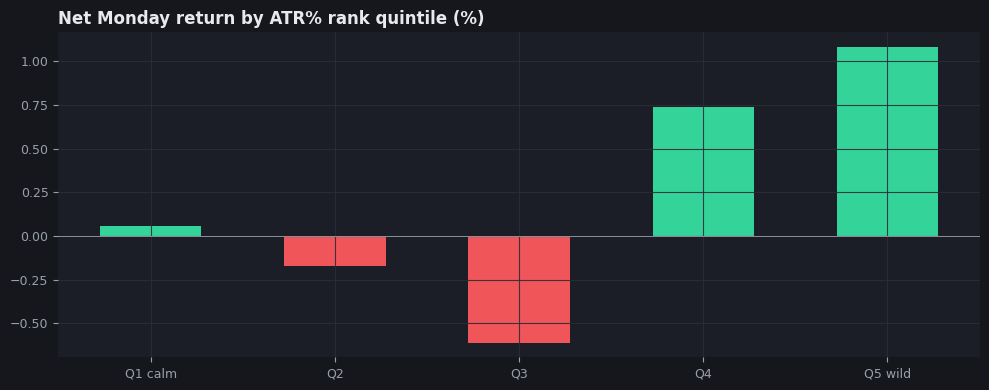

In [49]:
q = naked_n.dropna(subset=["atr_rank"]).copy()
q["quintile"] = pd.qcut(q["atr_rank"], 5, labels=["Q1 calm", "Q2", "Q3", "Q4", "Q5 wild"])
qt = q.groupby("quintile", observed=True).agg(Mondays=("pnl", "size"), rank_from=("atr_rank", "min"), rank_to=("atr_rank", "max"),
                                              net_mean=("pnl", "mean"), hit=("win", "mean"))
qt["net_t"] = q.groupby("quintile", observed=True)["pnl"].apply(tstat)
qt["hit"] *= 100
rho, p_rho = stats.spearmanr(q["atr_rank"], q["pnl"])
print("=" * 70)
print("NET MONDAY RETURN BY ATR% RANK QUINTILE (whole history)")
print("=" * 70)
display(qt.round(3))
print(f"Spearman rho (atr_rank vs net Monday return): {rho:+.3f} (p = {p_rho:.3f})")

# What the filter really does: rank >= P/100 is NOT "the top (100-P)% of Mondays" (Sunday-23:00 ranks are not uniform)
kept = q.loc[q["atr_rank"] >= ATR_PCTL / 100, "pnl"]
skipped = q.loc[q["atr_rank"] < ATR_PCTL / 100, "pnl"]
print(f"Filter threshold: atr_rank >= {ATR_PCTL/100:.2f}  ->  trades {len(kept)} of {len(q)} Mondays ({len(kept)/len(q):.0%}), skips {len(skipped)}")
print(f"Net mean per Monday: kept {kept.mean():+.3f}% | skipped {skipped.mean():+.3f}%")

# same table inside the ETF era only (is the volatility effect era-specific?)
q_etf = q[q["era"] == ERA_E]
if len(q_etf) >= 25:
    rho_e, p_e = stats.spearmanr(q_etf["atr_rank"], q_etf["pnl"])
    print(f"Spearman rho, ETF era only ({len(q_etf)} Mondays): {rho_e:+.3f} (p = {p_e:.3f})")

# ---- PASS / FAIL ----
print("\nCHECKS (4.3):")
t_ks, p_ks = stats.ttest_ind(kept, skipped, equal_var=False, alternative="greater")
check("4.3 Volatility", f"ATR% rank correlates positively with net return (p < {ALPHA:g})", rho > 0 and p_rho < ALPHA,
      f"rho = {rho:+.3f}, p = {p_rho:.3f}")
if len(q_etf) >= 25:
    check("4.3 Volatility", f"Same in the ETF era only (p < {ALPHA:g})", rho_e > 0 and p_e < ALPHA,
          f"rho = {rho_e:+.3f}, p = {p_e:.3f} ({len(q_etf)} Mondays)")
else:
    check("4.3 Volatility", "Same in the ETF era only", None, f"only {len(q_etf)} ETF-era Mondays")
check("4.3 Volatility", f"Kept Mondays beat skipped Mondays (one-sided Welch p < {ALPHA:g})", kept.mean() > skipped.mean() and p_ks < ALPHA,
      f"kept {kept.mean():+.3f}% vs skipped {skipped.mean():+.3f}% | t = {t_ks:.2f}, p = {p_ks:.3f}")
check("4.3 Volatility", "Skipped Mondays do not cover costs (net mean <= 0)", skipped.mean() <= 0,
      f"skipped net mean {skipped.mean():+.3f}% over {len(skipped)} Mondays")
check("4.3 Volatility", "Calmest quintile (Q1) does not cover costs (net mean <= 0)", qt["net_mean"].iloc[0] <= 0,
      f"Q1 net mean {qt['net_mean'].iloc[0]:+.3f}% (t = {qt['net_t'].iloc[0]:.2f})")
check("4.3 Volatility", "Net return rises with the quintile (monotonic)", qt["net_mean"].is_monotonic_increasing,
      " -> ".join(f"{v:+.2f}" for v in qt["net_mean"]))

BG, PANEL, GRIDC, TXT, SUB, GREEN, RED, ORANGE = "#15171c", "#1b1e26", "#2a2d37", "#e8e9ec", "#9aa0ab", "#34d399", "#f0555a", "#f5a524"
def dark_ax(ax):
    ax.set_facecolor(PANEL); ax.grid(True, color=GRIDC, lw=0.8, alpha=0.9)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(colors=SUB, labelsize=9)

fig, ax = plt.subplots(figsize=(10, 4), facecolor=BG)
dark_ax(ax)
ax.bar(range(len(qt)), qt["net_mean"], color=[GREEN if v > 0 else RED for v in qt["net_mean"]], width=0.55)
ax.axhline(0, color=SUB, lw=0.6)
ax.set_xticks(range(len(qt))); ax.set_xticklabels(qt.index, color=SUB)
ax.set_title("Net Monday return by ATR% rank quintile (%)", color=TXT, fontweight="bold", loc="left")
plt.tight_layout(); plt.show()

### 4.4 FIRST MONDAY OF THE MONTH VS THE REST

In [50]:
naked_n["first_monday"] = pd.to_datetime(naked_n["entry_time"]).dt.day <= 7
fm = naked_n.pivot_table(index="era", columns="first_monday", values="pnl", aggfunc=["mean", "size"])
fm = fm.reindex(list(ERAS))
fm_tbl = pd.DataFrame({"Rest: mean %": fm[("mean", False)], "Rest: N": fm[("size", False)],
                       "First Monday: mean %": fm[("mean", True)], "First Monday: N": fm[("size", True)]})
print("=" * 70)
print("NET MONDAY RETURN: FIRST MONDAY OF THE MONTH VS THE REST (by era)")
print("=" * 70)
display(fm_tbl.round(3))
fm_all = naked_n.loc[naked_n["first_monday"], "pnl"]
rest_all = naked_n.loc[~naked_n["first_monday"], "pnl"]
print("All eras | first Monday mean %:", round(fm_all.mean(), 3), "| rest mean %:", round(rest_all.mean(), 3))

# ---- PASS / FAIL ----
print("\nCHECKS (4.4):")
t_fm, p_fm = stats.ttest_ind(fm_all, rest_all, equal_var=False, alternative="less")
worse = fm_tbl["First Monday: mean %"] < fm_tbl["Rest: mean %"]
check("4.4 First Monday", "First Monday is worse than the rest (all eras)", fm_all.mean() < rest_all.mean(),
      f"first {fm_all.mean():+.3f}% vs rest {rest_all.mean():+.3f}%")
check("4.4 First Monday", f"The difference is significant (one-sided Welch p < {ALPHA:g})", fm_all.mean() < rest_all.mean() and p_fm < ALPHA,
      f"t = {t_fm:.2f}, p = {p_fm:.3f} (N = {len(fm_all)} vs {len(rest_all)})")
check("4.4 First Monday", "First Monday is worse than the rest in every era", worse.all(),
      "; ".join(f"{e}: {'worse' if w else 'better'}" for e, w in worse.items()))

NET MONDAY RETURN: FIRST MONDAY OF THE MONTH VS THE REST (by era)


,Rest: mean %,Rest: N,First Monday: mean %,First Monday: N
era,,,,
Retail (2017-19),0.722,100,-0.543,27
Institutional (2020-23),0.098,159,0.633,48
ETF (2024+),0.445,112,-0.028,32


All eras | first Monday mean %: 0.138 | rest mean %: 0.371

CHECKS (4.4):
   [PASS] First Monday is worse than the rest (all eras)  ->  first +0.138% vs rest +0.371%
   [FAIL] The difference is significant (one-sided Welch p < 0.05)  ->  t = -0.56, p = 0.289 (N = 107 vs 371)
   [FAIL] First Monday is worse than the rest in every era  ->  Retail (2017-19): worse; Institutional (2020-23): better; ETF (2024+): worse


'FAIL'

## 5. BASELINE BACKTEST WITH FROZEN RULES

PERFORMANCE SUMMARY (NET OF 5.5 BPS PER SIDE · daily MTM drawdown, Sharpe annualised x365)


,Period,Sizing,Trades,Win Rate,Profit Factor,Expectancy,Total Return,CAGR,Sharpe,Max Drawdown
0,In-Sample (2017-2024),100% Capital,78,52.6%,1.653,1.172%,115.5%,12.2%,0.66,-29.18%
1,In-Sample (2017-2024),20% Capital (robot),78,52.6%,1.653,0.234%,18.8%,2.6%,0.65,-6.56%
2,Out-of-Sample (2024-2026),100% Capital,40,80.0%,6.451,1.703%,94.0%,26.8%,2.09,-3.61%
3,Out-of-Sample (2024-2026),20% Capital (robot),40,80.0%,6.451,0.341%,14.6%,5.0%,2.12,-0.72%
4,Full Period (2017-2026),100% Capital,118,61.9%,2.047,1.352%,318.0%,16.3%,0.90,-29.18%
5,Full Period (2017-2026),20% Capital (robot),118,61.9%,2.047,0.270%,36.1%,3.3%,0.90,-6.56%


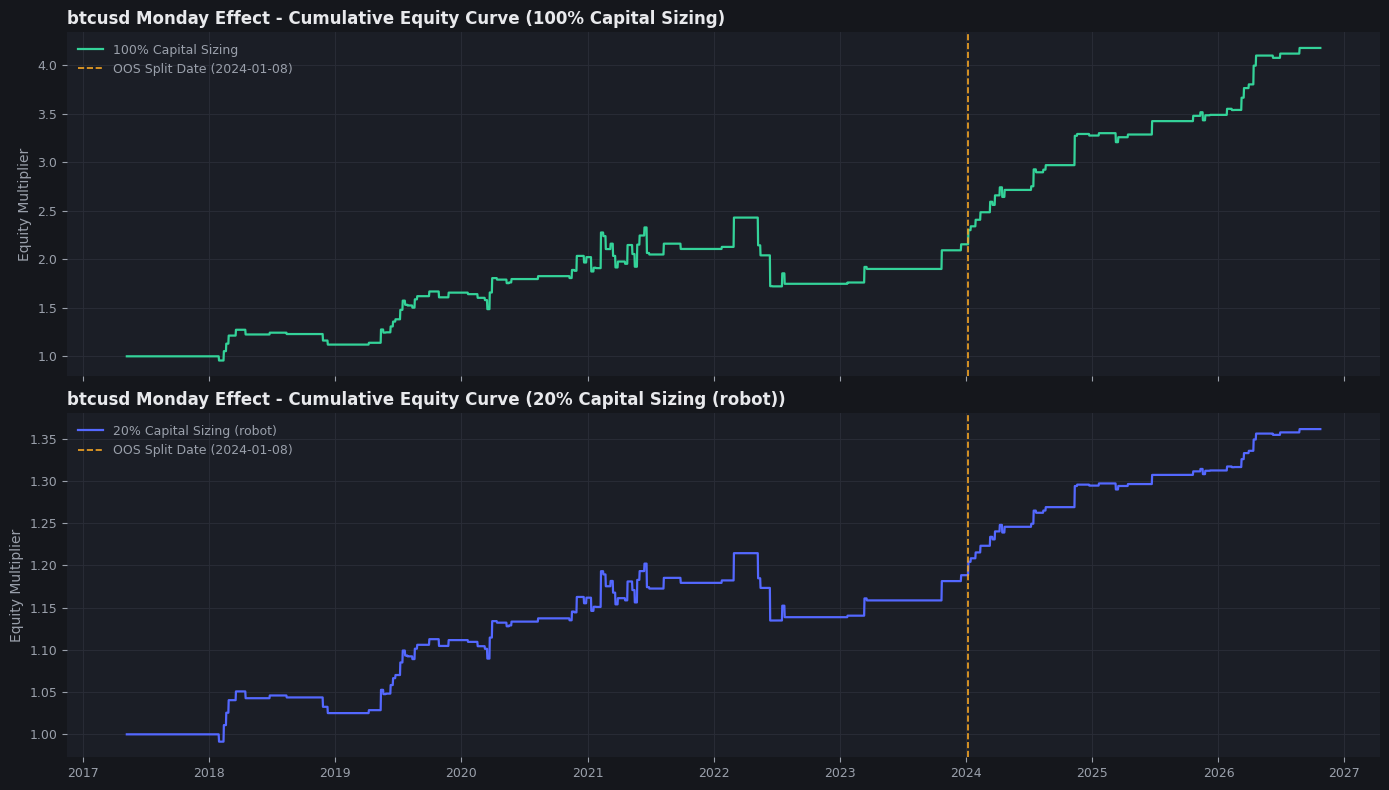

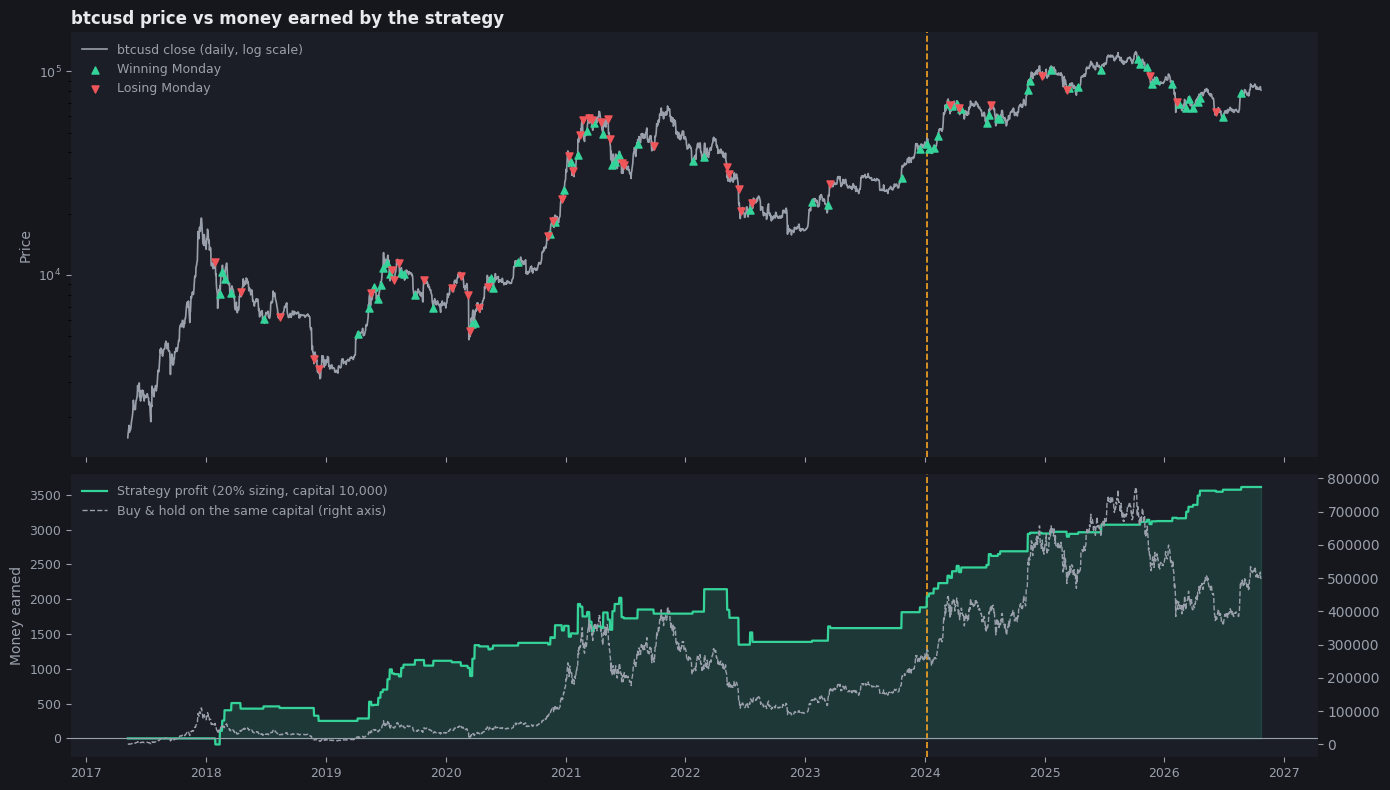

btcusd price change: +4,978% | strategy profit: 3,613 (+36.1% of 10,000) | buy & hold profit: 497,771 | time in market: 3.7%

CHECKS (5):
   [PASS] Profit Factor, full period >= 1.3  ->  PF = 2.047
   [PASS] Profit Factor, IS >= 1.3  ->  PF = 1.653
   [PASS] Profit Factor, OOS >= 1.3  ->  PF = 6.451
   [PASS] OOS does not degrade vs IS (OOS PF >= 50% of IS PF)  ->  OOS 6.451 vs IS 1.653
   [PASS] t-stat of the mean trade >= 2  ->  t = 2.82
   [PASS] Trades, full period >= 100  ->  118 trades
   [PASS] Trades, OOS >= 30  ->  40 trades
   [PASS] Expectancy > 0 in IS and OOS (net of costs)  ->  IS +1.172% | OOS +1.703%


'PASS'

In [51]:
trades_is  = eng.run_monday_backtest(df_is,  **RULES)
trades_oos = eng.run_monday_backtest(df_oos, **RULES)
trades_all = eng.run_monday_backtest(df,     **RULES)

def sized(t, sizing):
    return t if sizing == "capital" else t.assign(pnl=t["pnl_frac"], win=t["pnl_frac"] > 0)

def perf_row(t, price_df, period, sizing):
    m = compute_metrics(sized(t, sizing), contract_multiplier=1.0, cost_per_trade=0.0)
    ret = eng.daily_returns(price_df, t, sizing=sizing)
    eq = (1.0 + ret).cumprod()
    yrs = (price_df.index[-1] - price_df.index[0]).days / 365.25
    return {"Period": period, "Sizing": "100% Capital" if sizing == "capital" else f"{SIZE_FRAC:.0%} Capital (robot)",
            "Trades": m["num_trades"], "Win Rate": f"{m['win_rate']:.1f}%", "Profit Factor": f"{m['profit_factor']:.3f}",
            "Expectancy": f"{m['expectancy']:.3f}%", "Total Return": f"{(eq.iloc[-1] - 1) * 100:.1f}%",
            "CAGR": f"{((eq.iloc[-1] ** (1 / yrs)) - 1) * 100:.1f}%" if yrs > 0 else "n/a",
            "Sharpe": f"{sharpe_ratio(ret, periods_per_year=PPY):.2f}", "Max Drawdown": f"{max_drawdown(eq) * 100:.2f}%"}

periods = [(f"In-Sample ({df_is.index[0].year}-{df_is.index[-1].year})", trades_is, df_is),
           (f"Out-of-Sample ({df_oos.index[0].year}-{df_oos.index[-1].year})", trades_oos, df_oos),
           (f"Full Period ({df.index[0].year}-{df.index[-1].year})", trades_all, df)]
perf_table = pd.DataFrame([perf_row(t, d, name, s) for name, t, d in periods for s in ("capital", "fraction")])

print("=" * 80)
print(f"PERFORMANCE SUMMARY (NET OF {COST_BPS:g} BPS PER SIDE · daily MTM drawdown, Sharpe annualised x{PPY})")
print("=" * 80)
display(perf_table)

ret_cap = eng.daily_returns(df, trades_all, sizing="capital")
ret_fr = eng.daily_returns(df, trades_all, sizing="fraction")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, facecolor=BG)
for ax, r, col, lab in ((ax1, ret_cap, GREEN, "100% Capital Sizing"), (ax2, ret_fr, "#5468ff", f"{SIZE_FRAC:.0%} Capital Sizing (robot)")):
    dark_ax(ax)
    ax.plot(r.index, (1 + r).cumprod(), color=col, lw=1.6, label=lab)
    ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.2, label=f"OOS Split Date ({oos_start:%Y-%m-%d})")
    ax.set_title(f"{TICKER} Monday Effect - Cumulative Equity Curve ({lab})", color=TXT, fontweight="bold", loc="left")
    ax.set_ylabel("Equity Multiplier", color=SUB)
    ax.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

profit_usd = CAPITAL * ((1.0 + ret_fr).cumprod() - 1.0)
price_daily = df["close"].resample("D").last().reindex(ret_fr.index).ffill().bfill()
buy_hold = CAPITAL * (price_daily / price_daily.iloc[0] - 1.0)
entries = trades_all.assign(entry_time=pd.to_datetime(trades_all["entry_time"])).set_index("entry_time")
won = entries["pnl"] > 0

fig, (ax_px, ax_pl) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, facecolor=BG, gridspec_kw={"height_ratios": [3, 2]})
for ax in (ax_px, ax_pl):
    dark_ax(ax)
    ax.grid(False)
    ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.2)
ax_px.plot(price_daily.index, price_daily, color=SUB, lw=1.2, label=f"{TICKER} close (daily, log scale)")
ax_px.set_yscale("log")
ax_px.scatter(entries.index[won], entries.loc[won, "entry_price"], marker="^", s=26, color=GREEN, zorder=3, label="Winning Monday")
ax_px.scatter(entries.index[~won], entries.loc[~won, "entry_price"], marker="v", s=26, color=RED, zorder=3, label="Losing Monday")
ax_px.set_title(f"{TICKER} price vs money earned by the strategy", color=TXT, fontweight="bold", loc="left")
ax_px.set_ylabel("Price", color=SUB)
ax_px.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
ax_pl.plot(profit_usd.index, profit_usd, color=GREEN, lw=1.6, label=f"Strategy profit ({SIZE_FRAC:.0%} sizing, capital {CAPITAL:,.0f})")
ax_pl.fill_between(profit_usd.index, profit_usd, 0, color=GREEN, alpha=0.15)
ax_pl.axhline(0, color=SUB, lw=0.8)
ax_pl.set_ylabel("Money earned", color=SUB)
ax_bh = ax_pl.twinx()
ax_bh.plot(buy_hold.index, buy_hold, color=SUB, lw=1.0, ls="--", label="Buy & hold on the same capital (right axis)")
ax_bh.grid(False)
ax_bh.tick_params(colors=SUB)
for spine in ax_bh.spines.values():
    spine.set_visible(False)
h1, l1 = ax_pl.get_legend_handles_labels()
h2, l2 = ax_bh.get_legend_handles_labels()
ax_pl.legend(h1 + h2, l1 + l2, frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

in_market = float(trades_all["bars"].sum()) / len(df)
print(f"{TICKER} price change: {(price_daily.iloc[-1] / price_daily.iloc[0] - 1) * 100:+,.0f}% | "
      f"strategy profit: {profit_usd.iloc[-1]:,.0f} ({profit_usd.iloc[-1] / CAPITAL * 100:+.1f}% of {CAPITAL:,.0f}) | "
      f"buy & hold profit: {buy_hold.iloc[-1]:,.0f} | time in market: {in_market * 100:.1f}%")

# ---- PASS / FAIL ----
print("\nCHECKS (5):")
m_is, m_oos, m_all = (compute_metrics(t, 1.0, 0.0) for t in (trades_is, trades_oos, trades_all))
t_all = tstat(trades_all["pnl"])
check("5. Baseline", f"Profit Factor, full period >= {PF_MIN:g}", m_all["profit_factor"] >= PF_MIN, f"PF = {m_all['profit_factor']:.3f}")
check("5. Baseline", f"Profit Factor, IS >= {PF_MIN:g}", m_is["profit_factor"] >= PF_MIN, f"PF = {m_is['profit_factor']:.3f}")
check("5. Baseline", f"Profit Factor, OOS >= {PF_MIN:g}", m_oos["profit_factor"] >= PF_MIN, f"PF = {m_oos['profit_factor']:.3f}")
check("5. Baseline", "OOS does not degrade vs IS (OOS PF >= 50% of IS PF)", m_oos["profit_factor"] >= 0.5 * m_is["profit_factor"],
      f"OOS {m_oos['profit_factor']:.3f} vs IS {m_is['profit_factor']:.3f}")
check("5. Baseline", f"t-stat of the mean trade >= {T_MIN:g}", t_all >= T_MIN, f"t = {t_all:.2f}")
check("5. Baseline", f"Trades, full period >= {N_MIN}", m_all["num_trades"] >= N_MIN, f"{m_all['num_trades']} trades")
check("5. Baseline", f"Trades, OOS >= {N_OOS_MIN}", m_oos["num_trades"] >= N_OOS_MIN, f"{m_oos['num_trades']} trades")
check("5. Baseline", "Expectancy > 0 in IS and OOS (net of costs)", m_is["expectancy"] > 0 and m_oos["expectancy"] > 0,
      f"IS {m_is['expectancy']:+.3f}% | OOS {m_oos['expectancy']:+.3f}%")

## 5.1 LOT-ADJUSTED SIZING AND HARD LIMIT (CFD):

HARD LIMIT -9% · LOT-ADJUSTED SIZING (min lot 0.01, step 0.01)


,Sizing,Trades taken,Total Return,Max DD (hourly MTM),Headroom,Hard limit
0,20% ideal fraction,118,36.1%,-7.33%,+1.67 pts,PASS
1,"Lot-adjusted (capital 10,000)",118,32.9%,-6.95%,+2.05 pts,PASS


Minimum capital so the minimum lot weighs <= 20% at 80,730: 4,037
Largest fixed fraction that keeps the hourly drawdown inside -9%: 24.8% (configured: 20%)

CHECKS (5.1):
   [PASS] 20% ideal fraction stays inside -9%  ->  max DD -7.33% | headroom +1.67 pts
   [PASS] Lot-adjusted sizing stays inside -9%  ->  max DD -6.95% | headroom +2.05 pts
   [PASS] Configured fraction <= largest fraction allowed by the limit  ->  20% vs 24.8%
   [PASS] Capital >= minimum capital for the minimum lot  ->  10,000 vs 4,037
   [PASS] Every trade is executable with the minimum lot  ->  118 of 118 trades taken


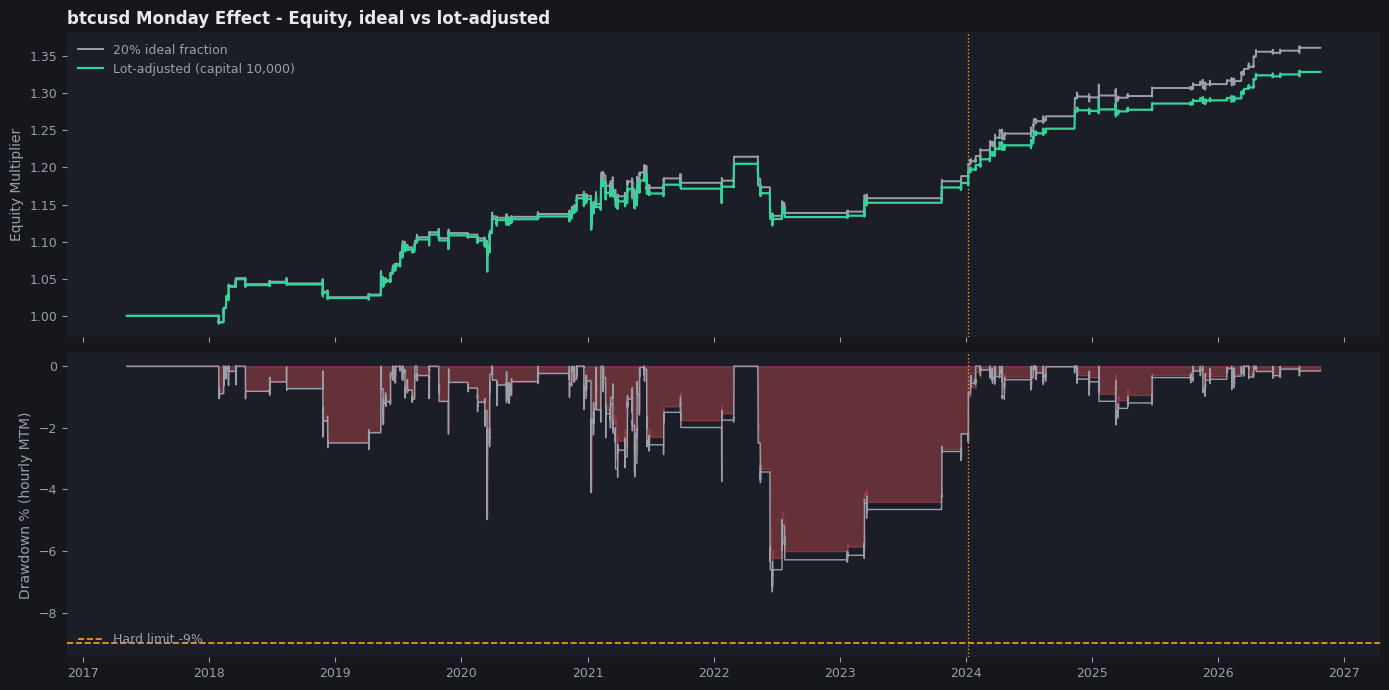

In [52]:
last_price = float(df["close"].iloc[-1])
min_capital = eng.min_capital_for_target(last_price, SIZE_FRAC)
max_frac = eng.max_fraction_for_limit(df, trades_all, HARD_LIMIT)
lot_sizes = eng.cfd_trade_sizes(trades_all, CAPITAL, SIZE_FRAC)
hourly_ideal = eng.hourly_returns(df, trades_all, sizing="fraction")
hourly_lot = eng.hourly_returns(df, trades_all, sizing=lot_sizes["size_fraction"].to_numpy())

def drawdown_series(hourly):
    eq = (1.0 + hourly).cumprod()
    return eq / np.maximum(eq.cummax(), 1.0) - 1.0

def limit_row(label, hourly, n_taken):
    rep = eng.hard_limit_report(hourly, HARD_LIMIT)
    total = (1.0 + hourly).prod() - 1.0
    return {"Sizing": label, "Trades taken": n_taken, "Total Return": f"{total * 100:.1f}%",
            "Max DD (hourly MTM)": f"{rep['max_dd'] * 100:.2f}%", "Headroom": f"{rep['headroom'] * 100:+.2f} pts",
            "Hard limit": "PASS" if rep["passed"] else "FAIL"}

limit_table = pd.DataFrame([
    limit_row(f"{SIZE_FRAC:.0%} ideal fraction", hourly_ideal, len(trades_all)),
    limit_row(f"Lot-adjusted (capital {CAPITAL:,.0f})", hourly_lot, int(lot_sizes["taken"].sum()))])

print("=" * 80)
print(f"HARD LIMIT -{HARD_LIMIT:.0%} · LOT-ADJUSTED SIZING (min lot {MIN_LOT:g}, step {LOT_STEP:g})")
print("=" * 80)
display(limit_table)
print(f"Minimum capital so the minimum lot weighs <= {SIZE_FRAC:.0%} at {last_price:,.0f}: {min_capital:,.0f}")
print(f"Largest fixed fraction that keeps the hourly drawdown inside -{HARD_LIMIT:.0%}: {max_frac:.1%} (configured: {SIZE_FRAC:.0%})")

# ---- PASS / FAIL ----
print("\nCHECKS (5.1):")
rep_ideal = eng.hard_limit_report(hourly_ideal, HARD_LIMIT)
rep_lot = eng.hard_limit_report(hourly_lot, HARD_LIMIT)
check("5.1 Hard limit", f"{SIZE_FRAC:.0%} ideal fraction stays inside -{HARD_LIMIT:.0%}", rep_ideal["passed"],
      f"max DD {rep_ideal['max_dd'] * 100:.2f}% | headroom {rep_ideal['headroom'] * 100:+.2f} pts")
check("5.1 Hard limit", f"Lot-adjusted sizing stays inside -{HARD_LIMIT:.0%}", rep_lot["passed"],
      f"max DD {rep_lot['max_dd'] * 100:.2f}% | headroom {rep_lot['headroom'] * 100:+.2f} pts")
check("5.1 Hard limit", "Configured fraction <= largest fraction allowed by the limit", SIZE_FRAC <= max_frac,
      f"{SIZE_FRAC:.0%} vs {max_frac:.1%}")
check("5.1 Hard limit", "Capital >= minimum capital for the minimum lot", CAPITAL >= min_capital,
      f"{CAPITAL:,.0f} vs {min_capital:,.0f}")
check("5.1 Hard limit", "Every trade is executable with the minimum lot", int(lot_sizes["taken"].sum()) == len(trades_all),
      f"{int(lot_sizes['taken'].sum())} of {len(trades_all)} trades taken")

dd_ideal, dd_lot = drawdown_series(hourly_ideal), drawdown_series(hourly_lot)
fig, (ax_eq, ax_dd) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, facecolor=BG)
for ax in (ax_eq, ax_dd):
    dark_ax(ax)
    ax.grid(False)
    ax.axvline(oos_start, color=ORANGE, ls=":", lw=1.0)
ax_eq.plot(hourly_ideal.index, (1.0 + hourly_ideal).cumprod(), color=SUB, lw=1.4, label=f"{SIZE_FRAC:.0%} ideal fraction")
ax_eq.plot(hourly_lot.index, (1.0 + hourly_lot).cumprod(), color=GREEN, lw=1.6, label=f"Lot-adjusted (capital {CAPITAL:,.0f})")
ax_eq.set_title(f"{TICKER} Monday Effect - Equity, ideal vs lot-adjusted", color=TXT, fontweight="bold", loc="left")
ax_eq.set_ylabel("Equity Multiplier", color=SUB)
ax_eq.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
ax_dd.plot(dd_ideal.index, dd_ideal * 100, color=SUB, lw=1.0)
ax_dd.fill_between(dd_lot.index, dd_lot * 100, 0, color=RED, alpha=0.35)
ax_dd.axhline(-HARD_LIMIT * 100, color=ORANGE, ls="--", lw=1.2, label=f"Hard limit -{HARD_LIMIT:.0%}")
ax_dd.set_ylabel("Drawdown % (hourly MTM)", color=SUB)
ax_dd.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="lower left")
plt.tight_layout(); plt.show()

## 5.2 ANNUAL RETURNS AND HARD LIMIT CHECK

ANNUAL RETURNS · LOT-ADJUSTED · HARD LIMIT -9% · * = partial year


,year,ret,mdd,n_trades,partial,breach
0,2017,+0.0%,0.0%,0,True,False
1,2018,+2.4%,-2.6%,10,False,False
2,2019,+8.2%,-2.2%,17,False,False
3,2020,+4.4%,-4.4%,17,False,False
4,2021,+1.2%,-3.6%,21,False,False
5,2022,-3.3%,-6.9%,8,False,False
6,2023,+4.1%,-0.6%,5,False,False
7,2024,+8.2%,-0.9%,18,False,False
8,2025,+1.1%,-1.6%,11,False,False
9,2026,+3.0%,-0.6%,11,True,False


Steps below the limit: 0 | first breach: None

CHECKS (5.2):
   [PASS] No calendar year breaches the hard limit  ->  years in breach: none | worst year DD -6.9%
   [PASS] >= 75% of full calendar years are profitable  ->  7/8 full years positive | non-positive: 2022 (-3.3%)


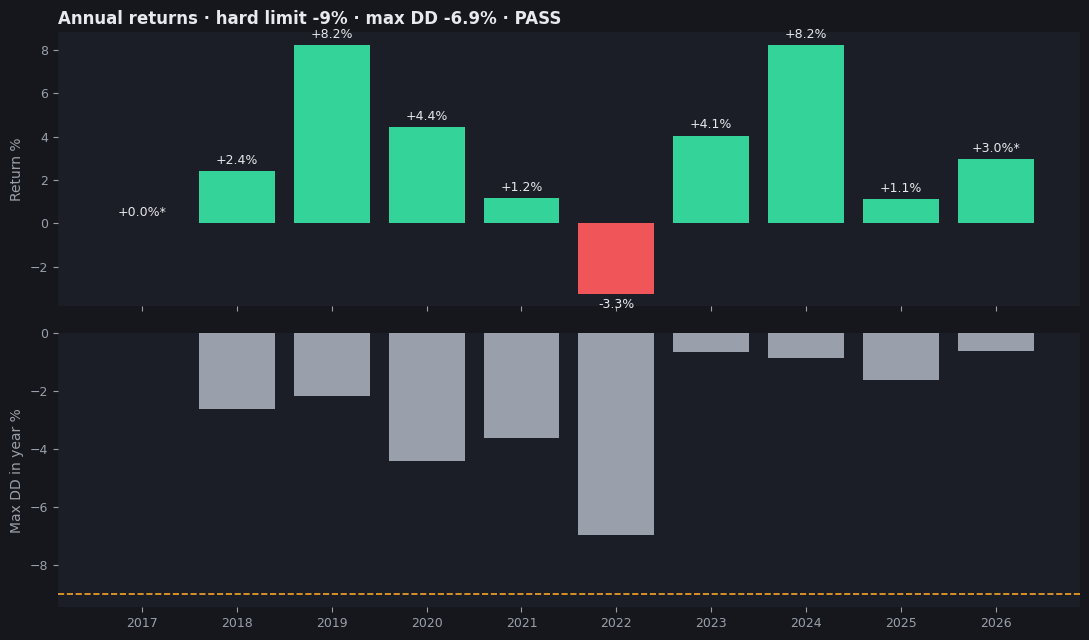

In [53]:
def plot_annual_returns(annual, report, hard_limit):
    fig, (ax_ret, ax_dd) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, facecolor=BG)
    years = annual["year"].astype(str).to_numpy()
    ret_colors = [GREEN if v >= 0 else RED for v in annual["ret"]]
    bars = ax_ret.bar(years, annual["ret"] * 100, color=ret_colors)
    dd_colors = [RED if b else SUB for b in annual["breach"]]
    ax_dd.bar(years, annual["mdd"] * 100, color=dd_colors)
    ax_dd.axhline(-hard_limit * 100, color=ORANGE, ls="--", lw=1.2)
    for ax in (ax_ret, ax_dd):
        dark_ax(ax)
        ax.grid(False)
    for rect, value, partial in zip(bars, annual["ret"], annual["partial"]):
        label = f"{value:+.1%}" + ("*" if partial else "")
        ax_ret.annotate(label, (rect.get_x() + rect.get_width() / 2, value * 100),
                        xytext=(0, 3 if value >= 0 else -3), textcoords="offset points",
                        ha="center", va="bottom" if value >= 0 else "top", color=TXT, fontsize=9)
    status = "PASS" if report["passed"] else "FAIL"
    ax_ret.set_title(f"Annual returns · hard limit -{hard_limit:.0%} · max DD {report['max_dd']:.1%} · {status}",
                     color=TXT, fontweight="bold", loc="left")
    ax_ret.set_ylabel("Return %", color=SUB)
    ax_dd.set_ylabel("Max DD in year %", color=SUB)
    plt.tight_layout(); plt.show()

annual = eng.annual_returns(hourly_lot, trades_all, HARD_LIMIT)
report_annual = eng.hard_limit_report(hourly_lot, HARD_LIMIT)

print("=" * 80)
print(f"ANNUAL RETURNS · LOT-ADJUSTED · HARD LIMIT -{HARD_LIMIT:.0%} · * = partial year")
print("=" * 80)
display(annual.style.format({"ret": "{:+.1%}", "mdd": "{:.1%}"}))
print(f"Steps below the limit: {report_annual['steps_in_breach']} | first breach: {report_annual['first_breach']}")

# ---- PASS / FAIL ----
print("\nCHECKS (5.2):")
full_y = annual[~annual["partial"]]
neg = full_y[full_y["ret"] <= 0]
n_pos = len(full_y) - len(neg)
breach_years = annual.loc[annual["breach"], "year"].astype(int).tolist()
check("5.2 Annual", "No calendar year breaches the hard limit", not annual["breach"].any(),
      f"years in breach: {breach_years if breach_years else 'none'} | worst year DD {annual['mdd'].min() * 100:.1f}%")
check("5.2 Annual", f">= {YEARS_POS_MIN:.0%} of full calendar years are profitable", n_pos / len(full_y) >= YEARS_POS_MIN,
      f"{n_pos}/{len(full_y)} full years positive" + (" | non-positive: " + ", ".join(f"{int(y)} ({r:+.1%})" for y, r in zip(neg["year"], neg["ret"])) if len(neg) else ""))

plot_annual_returns(annual, report_annual, HARD_LIMIT)

## 6. SANITY CHECKS & VERIFICATION

In [54]:
print("=" * 70)
print("SANITY CHECKS & REPRODUCIBILITY")
print("=" * 70)

# 1. No lookahead + execution model (violations are collected, not asserted, so the notebook keeps running)
violations, prev_end = [], None
for idx_, r in trades_all.iterrows():
    et, xt = pd.Timestamp(r["entry_time"]), pd.Timestamp(r["exit_time"])
    sig_time = df.index[int(r["i_ent"]) - 1]
    if sig_time != et - pd.Timedelta(hours=1):
        violations.append(f"trade {idx_}: signal bar is not the previous hour")
    if not (df.index[int(r["i_ent"])] == et and df.index[int(r["i_sal"])] == xt):
        violations.append(f"trade {idx_}: i_ent / i_sal misaligned")
    if not (et.dayofweek == 0 and et.hour == ENTRY_HOUR):
        violations.append(f"trade {idx_}: entry is not Monday {ENTRY_HOUR}:00")
    if xt - et != pd.Timedelta(hours=HOLD):
        violations.append(f"trade {idx_}: holding is not {HOLD} h")
    if SKIP1 and et.day <= 7:
        violations.append(f"trade {idx_}: first Monday traded")
    if not np.isclose(r["entry_price"], df.loc[et, "open"] * (1 + COST_BPS / 1e4), atol=1e-6):
        violations.append(f"trade {idx_}: entry price mismatch")
    if prev_end is not None and et < prev_end:
        violations.append(f"trade {idx_}: overlaps the previous trade")
    prev_end = xt
print(f"Sanity Check 1: no lookahead, Monday {ENTRY_HOUR:02d}:00 UTC entry, {HOLD} h hold, no overlap ({len(trades_all)} trades).")
print("   - Signal evaluated at the close of the previous hourly bar (Sunday 23:00 UTC).")
print(f"   - Execution at the open with +{COST_BPS:g} bps per side.")
check("6. Sanity", "No lookahead and execution model respected on every trade", not violations,
      f"{len(trades_all)} trades checked" + (f" | {len(violations)} violations, first: {violations[0]}" if violations else ""))

# 2. Trade distribution per calendar year (full years only)
trades_all["year"] = pd.to_datetime(trades_all["entry_time"]).dt.year
tpy = trades_all.groupby("year").size()
full_years = [y for y in range(df.index[0].year, df.index[-1].year + 1)
              if pd.Timestamp(f"{y}-01-01") >= df.index[0] and pd.Timestamp(f"{y}-12-31") <= df.index[-1]]
tpy_full = tpy.reindex(full_years, fill_value=0)
print("\nSanity Check 2: Trade Frequency per Year:")
print(f"   - Average trades per year: {tpy.mean():.1f}")
print(f"   - Min trades (full years): {tpy_full.min()} ({tpy_full.idxmin()}) | Max trades: {tpy.max()} ({tpy.idxmax()})")
check("6. Sanity", f"Every full calendar year has >= {MIN_TRADES_PER_YEAR} trades", (tpy_full >= MIN_TRADES_PER_YEAR).all(),
      f"min {tpy_full.min()} ({tpy_full.idxmin()}) | max {tpy_full.max()} ({tpy_full.idxmax()}) over {len(tpy_full)} full years")

# 3. MTM paths reproduce the trade returns exactly
paths = eng.trade_mtm_paths(df, trades_all, sizing="capital")
err = max(abs(np.prod(1 + p) - (1 + pnl / 100)) for p, pnl in zip(paths, trades_all["pnl"]))
print(f"\nSanity Check 3: MTM paths telescope to trade returns (max abs error {err:.2e}).")
check("6. Sanity", "MTM paths telescope to the trade returns (error < 1e-9)", err < 1e-9, f"max abs error {err:.2e}")

# 4. Cross-check with the published reference (Sentinel engine: Binance BTCUSDT 1h from 17 Aug 2017, 14 bps per side)
BINANCE_CSV   = "../../../data/binance/BTCUSDT_1h.csv"    # the reference data, independent of this variant's own CSV
REF_END, REF_OOS_START = "2026-10-02", "2024-01-08"
REF = {"naked_all": 473, "naked_oos": 142, "n_all": 183, "n_oos": 56, "pf_all": 1.51, "pf_oos": 2.70}
TOL_REPRO_TRADES, TOL_REPRO_PF = 0.05, 0.05               # same data + same engine: should be (almost) identical
is_reference = (VOL_MODE, ATR_PCTL, ATR_LEN, SKIP1, ENTRY_HOUR, HOLD) == ("pctl", 30.0, 48, True, 0, 24)
print("\nSanity Check 4: Comparison with the published reference (Sentinel):")
if not is_reference:
    check("6. Sanity", "Matches the published reference", None, "skipped: not the reference v3 rules")
else:
    # 4a. The ENGINE on the REFERENCE data (Binance, 14 bps): validates the rules implemented in the engine
    try:
        raw_ref = eng.load_data(None, end=REF_END, csv_path=BINANCE_CSV)
    except FileNotFoundError:
        raw_ref = None
    repro_names = ("Trades, full period", "Profit Factor, full period", "Trades, OOS", "Profit Factor, OOS")
    if raw_ref is None:
        for lab in repro_names:
            check("6. Sanity", f"Matches the reference: {lab}", None, f"Binance CSV not found: {BINANCE_CSV}")
    else:
        d_ref = eng.prepare(raw_ref, atr_len=ATR_LEN, entry_hour=ENTRY_HOUR)
        t_ref = eng.run_monday_backtest(d_ref, **{**RULES, "cost_bps_per_side": REF_COST_BPS})
        t_ref_oos = t_ref[pd.to_datetime(t_ref["entry_time"]) >= pd.Timestamp(REF_OOS_START)]
        m_ra, m_ro = compute_metrics(t_ref, 1.0, 0.0), compute_metrics(t_ref_oos, 1.0, 0.0)
        repro = [("Trades, full period", len(t_ref), REF["n_all"], TOL_REPRO_TRADES),
                 ("Profit Factor, full period", m_ra["profit_factor"], REF["pf_all"], TOL_REPRO_PF),
                 ("Trades, OOS", len(t_ref_oos), REF["n_oos"], TOL_REPRO_TRADES),
                 ("Profit Factor, OOS", m_ro["profit_factor"], REF["pf_oos"], TOL_REPRO_PF)]
        print(f"   Engine on the reference data (Binance, {REF_COST_BPS:g} bps/side, up to {REF_END}):")
        display(pd.DataFrame([{"Metric": lab, "Engine (ours)": f"{ours:g}" if isinstance(ours, int) else f"{ours:.3f}",
                               "Reference": f"{ref:g}", "Diff": f"{ours / ref - 1:+.0%}"} for lab, ours, ref, _ in repro]))
        for lab, ours, ref, tol in repro:
            check("6. Sanity", f"Matches the reference: {lab} (±{tol:.0%})", abs(ours / ref - 1) <= tol,
                  f"ours {ours:g} vs reference {ref:g} ({ours / ref - 1:+.0%})")
        bars = pd.DataFrame({"this variant": df_raw.groupby(df_raw.index.year).size(),
                             "reference (Binance)": raw_ref.groupby(raw_ref.index.year).size()}).fillna(0).astype(int)
        print("   Hourly bars per year (gaps in this variant's data change ATR and percentile ranks):")
        display(bars.T)

    # 4b. THIS VARIANT's data vs the reference: do the same Mondays pass the filter? (informational)
    end_ts, oos_ts = pd.Timestamp(REF_END), pd.Timestamp(REF_OOS_START)
    nk = pd.to_datetime(naked_n["entry_time"]); nk = nk[nk <= end_ts]
    v3 = pd.to_datetime(trades_all["entry_time"]); v3 = v3[v3 <= end_ts]
    n_nk, n_nk_o, n_v3, n_v3_o = len(nk), int((nk >= oos_ts).sum()), len(v3), int((v3 >= oos_ts).sum())
    check("6. Sanity", "This variant's data: naked Mondays match the reference (±5%)",
          abs(n_nk / REF["naked_all"] - 1) <= 0.05 and abs(n_nk_o / REF["naked_oos"] - 1) <= 0.05,
          f"full {n_nk} vs {REF['naked_all']} | OOS {n_nk_o} vs {REF['naked_oos']}")
    check("6. Sanity", "This variant's data: v3 trades match the reference (±15%)",
          abs(n_v3 / REF["n_all"] - 1) <= REF_TOL_TRADES and abs(n_v3_o / REF["n_oos"] - 1) <= REF_TOL_TRADES,
          f"full {n_v3} vs {REF['n_all']} | OOS {n_v3_o} vs {REF['n_oos']} (same Mondays, the filter admits fewer)")

SANITY CHECKS & REPRODUCIBILITY
Sanity Check 1: no lookahead, Monday 00:00 UTC entry, 24 h hold, no overlap (118 trades).
   - Signal evaluated at the close of the previous hourly bar (Sunday 23:00 UTC).
   - Execution at the open with +5.5 bps per side.
   [PASS] No lookahead and execution model respected on every trade  ->  118 trades checked

Sanity Check 2: Trade Frequency per Year:
   - Average trades per year: 13.1
   - Min trades (full years): 5 (2023) | Max trades: 21 (2021)
   [PASS] Every full calendar year has >= 5 trades  ->  min 5 (2023) | max 21 (2021) over 8 full years

Sanity Check 3: MTM paths telescope to trade returns (max abs error 1.11e-15).
   [PASS] MTM paths telescope to the trade returns (error < 1e-9)  ->  max abs error 1.11e-15

Sanity Check 4: Comparison with the published reference (Sentinel):
   [SKIP] Matches the published reference  ->  skipped: not the reference v3 rules


## 7. REFERENCE VARIANTS: NAKED MONDAY VS v1 VS v3 (SAME BARS, SAME COSTS, SAME SIZE)

VARIANT COMPARISON (20% capital per trade, 5.5 bps/side)


,Variant,Trades,Win Rate,Profit Factor,Sharpe,Max Drawdown,Final Capital
0,Naked Monday (no filter),478,49.0%,1.253,0.55,-11.00%,1.32x
1,"v1 (ATR band 0.40-1.20, |ret24h| <= 4%)",255,52.2%,1.338,0.56,-10.60%,1.20x
2,"v3 (configured: P40, skip 1st Monday)",118,61.9%,2.047,0.90,-6.56%,1.36x



CHECKS (7):
   [PASS] v3 Profit Factor beats naked and v1  ->  v3 2.047 | naked 1.253 | v1 1.338
   [PASS] v3 expectancy per trade beats naked and v1  ->  v3 +1.352% | naked +0.319% | v1 +0.384%
   [PASS] v3 Sharpe beats naked and v1  ->  v3 0.90 | naked 0.55 | v1 0.56
   [PASS] v3 max drawdown is shallower than naked and v1  ->  v3 -6.56% | naked -11.00% | v1 -10.60%
   [PASS] v3 final capital is not below naked or v1 (1% tolerance)  ->  v3 1.361x | naked 1.324x | v1 1.204x


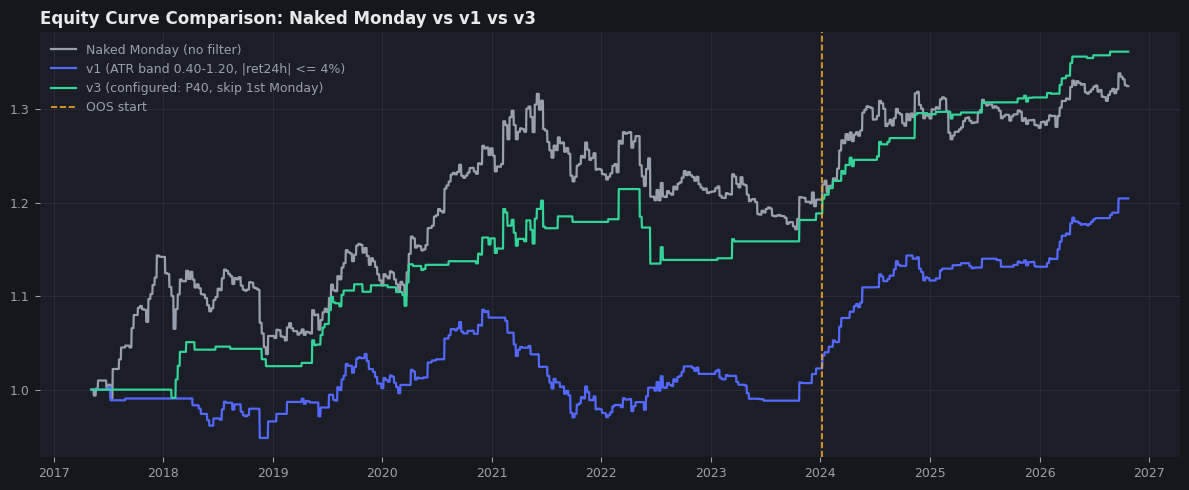

In [55]:
v_naked = eng.run_monday_backtest(df, cost_bps_per_side=COST_BPS, **naked_kw)
v_v1 = eng.run_monday_backtest(df, vol_mode="band", atr_band=(0.40, 1.20), max_abs_ret24_pct=4.0, skip_first_monday=False,
                               atr_len=ATR_LEN, entry_hour=ENTRY_HOUR, hold_bars=HOLD, cost_bps_per_side=COST_BPS)
variants = {"Naked Monday (no filter)": v_naked, "v1 (ATR band 0.40-1.20, |ret24h| <= 4%)": v_v1, f"v3 (configured: P{ATR_PCTL:g}, skip 1st Monday)": trades_all}

rows, curves, raw = [], {}, {}
for name, t in variants.items():
    m = compute_metrics(sized(t, "fraction"), 1.0, 0.0)
    mt = compute_metrics(t, 1.0, 0.0)                      # per-trade metrics at 100% capital
    r = eng.daily_returns(df, t, sizing="fraction")
    eq = (1 + r).cumprod()
    curves[name] = eq
    raw[name] = {"pf": mt["profit_factor"], "exp": mt["expectancy"], "sharpe": sharpe_ratio(r, periods_per_year=PPY),
                 "mdd": max_drawdown(eq), "final": float(eq.iloc[-1])}
    rows.append({"Variant": name, "Trades": m["num_trades"], "Win Rate": f"{m['win_rate']:.1f}%",
                 "Profit Factor": f"{mt['profit_factor']:.3f}", "Sharpe": f"{raw[name]['sharpe']:.2f}",
                 "Max Drawdown": f"{raw[name]['mdd'] * 100:.2f}%", "Final Capital": f"{eq.iloc[-1]:.2f}x"})
print("=" * 80)
print(f"VARIANT COMPARISON ({SIZE_FRAC:.0%} capital per trade, {COST_BPS:g} bps/side)")
print("=" * 80)
display(pd.DataFrame(rows))

# ---- PASS / FAIL ----
print("\nCHECKS (7):")
k_naked, k_v1, k_v3 = list(variants)
v3, others = raw[k_v3], (raw[k_naked], raw[k_v1])
check("7. Variants", "v3 Profit Factor beats naked and v1", all(v3["pf"] > o["pf"] for o in others),
      f"v3 {v3['pf']:.3f} | naked {raw[k_naked]['pf']:.3f} | v1 {raw[k_v1]['pf']:.3f}")
check("7. Variants", "v3 expectancy per trade beats naked and v1", all(v3["exp"] > o["exp"] for o in others),
      f"v3 {v3['exp']:+.3f}% | naked {raw[k_naked]['exp']:+.3f}% | v1 {raw[k_v1]['exp']:+.3f}%")
check("7. Variants", "v3 Sharpe beats naked and v1", all(v3["sharpe"] > o["sharpe"] for o in others),
      f"v3 {v3['sharpe']:.2f} | naked {raw[k_naked]['sharpe']:.2f} | v1 {raw[k_v1]['sharpe']:.2f}")
check("7. Variants", "v3 max drawdown is shallower than naked and v1", all(v3["mdd"] > o["mdd"] for o in others),
      f"v3 {v3['mdd'] * 100:.2f}% | naked {raw[k_naked]['mdd'] * 100:.2f}% | v1 {raw[k_v1]['mdd'] * 100:.2f}%")
check("7. Variants", "v3 final capital is not below naked or v1 (1% tolerance)", all(v3["final"] >= o["final"] * 0.99 for o in others),
      f"v3 {v3['final']:.3f}x | naked {raw[k_naked]['final']:.3f}x | v1 {raw[k_v1]['final']:.3f}x")

fig, ax = plt.subplots(figsize=(12, 5), facecolor=BG)
dark_ax(ax)
for (name, eq), col in zip(curves.items(), (SUB, "#5468ff", GREEN)):
    ax.plot(eq.index, eq, color=col, lw=1.6, label=name)
ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.2, label="OOS start")
ax.set_title("Equity Curve Comparison: Naked Monday vs v1 vs v3", color=TXT, fontweight="bold", loc="left")
ax.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

## 8. SUMMARY OF HYPOTHESIS & NEXT STEPS

In [56]:
m_all, m_is, m_oos = (compute_metrics(t, 1.0, 0.0) for t in (trades_all, trades_is, trades_oos))
t_all = tstat(trades_all["pnl"])
ret_fr_all = eng.daily_returns(df, trades_all, sizing="fraction")
max_dd_fr = max_drawdown((1 + ret_fr_all).cumprod()) * 100
years = (df.index[-1] - df.index[0]).days / 365.25
next_nb = "02_Monday_Optimization.ipynb"

# Core verdict (kept for the JSON of section 9): PF full and OOS, t-stat, N
confirmed = bool(m_all["profit_factor"] >= PF_MIN and m_oos["profit_factor"] >= PF_MIN and t_all >= T_MIN and m_all["num_trades"] >= N_MIN)
verdict = "Hypothesis Confirmed" if confirmed else "Hypothesis NOT clearly confirmed"
check("8. Verdict", f"Core criteria: PF >= {PF_MIN:g} (full and OOS), t >= {T_MIN:g}, N >= {N_MIN}", confirmed,
      f"PF {m_all['profit_factor']:.3f} / OOS {m_oos['profit_factor']:.3f} | t {t_all:.2f} | N {m_all['num_trades']}", quiet=True)

# ---- GO / STOP gate: only the checks that decide whether the research continues ----
# (section, start of the check name, what to do if it FAILS). Remove a line to stop treating it as a gate.
ESSENTIAL = [
    ("6. Sanity",       "No lookahead",                       "Fix the execution model / lookahead first: every other number is invalid until this passes."),
    ("6. Sanity",       "Matches the reference: Trades, OOS", "Reconcile the engine with the published reference (trade count in the same OOS window): review pctl_min_bars, the rank definition and the hourly gaps."),
    ("5. Baseline",     "Profit Factor, IS",                  "Baseline does not hold in-sample: the hypothesis is not supported, rethink the rules before optimizing."),
    ("5. Baseline",     "Profit Factor, OOS",                 "Baseline does not hold out-of-sample: do not optimize, the edge is not confirmed."),
    ("5. Baseline",     "t-stat of the mean trade",           "The mean trade is not statistically significant: the edge could be noise."),
    ("5. Baseline",     "Trades, full period",                "Too few trades to conclude anything."),
    ("5. Baseline",     "Trades, OOS",                        "Too few OOS trades to validate the edge."),
    ("4.3 Volatility",  "Kept Mondays beat skipped",          "The volatility filter does not add value over skipped Mondays: revisit the filter."),
    ("7. Variants",     "v3 Profit Factor beats",             "v3 does not beat naked / v1 on Profit Factor: the extra rules are not justified."),
    ("7. Variants",     "v3 max drawdown is shallower",       "v3 does not reduce drawdown vs naked / v1."),
    ("5.1 Hard limit",  "Lot-adjusted sizing stays inside",   "Lot-adjusted sizing breaks the hard limit: reduce the size fraction before going on."),
    ("5.1 Hard limit",  "Capital >= minimum capital",         "Capital is below what the minimum lot needs: raise capital or lower the target fraction."),
    ("5.2 Annual",      "No calendar year breaches",          "A calendar year breaches the hard limit: review sizing or the rules of that year."),
]

chk = pd.DataFrame(CHECKS)
n_pass, n_fail, n_skip = (int((chk["status"] == s).sum()) for s in ("PASS", "FAIL", "SKIP"))   # all checks (saved in section 9)
key = {(s, n): a for s, n, a in ESSENTIAL}
chk["essential"] = [any(sec == s and nm.startswith(n) for s, n, _ in ESSENTIAL) for sec, nm in zip(chk["section"], chk["name"])]
ess = chk[chk["essential"]]
other = chk[~chk["essential"] & (chk["section"] != "8. Verdict")]
missing = [f"{s}: {n}" for s, n, _ in ESSENTIAL if not ((chk["section"] == s) & chk["name"].str.startswith(n)).any()]
ess_fail = ess[ess["status"] == "FAIL"]
go = ess_fail.empty and not missing

print("=" * 80)
print("8. SUMMARY OF HYPOTHESIS & NEXT STEPS")
print("=" * 80)
print(f"\nDECISION: {'GO - continue the research' if go else 'STOP - fix the failed gates before continuing'}   "
      f"({int((ess['status'] == 'PASS').sum())} PASS / {len(ess_fail)} FAIL / {int((ess['status'] == 'SKIP').sum())} SKIP of {len(ESSENTIAL)} essential checks)"
      f"   |   {verdict}")
if missing:
    print("   Not run (run the sections above first): " + "; ".join(missing))

print("\n" + "-" * 80)
print("ESSENTIAL CHECKS")
print("-" * 80)
for sec, g in ess.groupby("section", sort=False):
    print(f"\n{sec}")
    for _, row in g.iterrows():
        print(f"   [{row['status']}] {row['name']}" + (f"  ->  {row['detail']}" if row["detail"] else ""))

print("\n" + "-" * 80)
print("KEY FINDINGS")
print("-" * 80)
print(f"""
1. {verdict}: {m_all['num_trades']} trades over {years:.0f}+ years, win rate {m_all['win_rate']:.1f}%, Profit Factor {m_all['profit_factor']:.3f}
   (IS {m_is['profit_factor']:.3f} / OOS {m_oos['profit_factor']:.3f}), t-stat of the mean trade {t_all:.2f}.

2. Era dependence: naked-Monday net mean by era -> """ + "; ".join(f"{e}: {naked_tbl.loc[e, 'Net mean %']:+.3f}% (t={naked_tbl.loc[e, 'Net t']:.2f})" for e in ERAS) + f""".

3. Volatility: Spearman rho between ATR% rank and net Monday return = {rho:+.3f} (p = {p_rho:.3f}); the filter trades {len(kept)/len(q):.0%} of Mondays.

4. Risk at {SIZE_FRAC:.0%} sizing: max daily-MTM drawdown {max_dd_fr:.2f}% over {df.index[0].year}-{df.index[-1].year}; hard limit -{HARD_LIMIT:.0%}.
""")

print("-" * 80)
print("NEXT STEPS")
print("-" * 80)
steps = [key[(r["section"], next(n for s, n, _ in ESSENTIAL if s == r["section"] and r["name"].startswith(n)))] for _, r in ess_fail.iterrows()]
if missing:
    steps.append("Run all the sections above so every essential check is evaluated.")
if go:
    steps.append(f"Proceed to {next_nb} to check that (P{ATR_PCTL:g}, ATR({ATR_LEN})) sits on a broad, stable plateau on in-sample data.")
for i, s in enumerate(steps, 1):
    print(f"{i}. {s}")

8. SUMMARY OF HYPOTHESIS & NEXT STEPS

DECISION: STOP - fix the failed gates before continuing   (12 PASS / 0 FAIL / 0 SKIP of 13 essential checks)   |   Hypothesis Confirmed
   Not run (run the sections above first): 6. Sanity: Matches the reference: Trades, OOS

--------------------------------------------------------------------------------
ESSENTIAL CHECKS
--------------------------------------------------------------------------------

4.3 Volatility
   [PASS] Kept Mondays beat skipped Mondays (one-sided Welch p < 0.05)  ->  kept +1.038% vs skipped -0.202% | t = 2.72, p = 0.004

5. Baseline
   [PASS] Profit Factor, IS >= 1.3  ->  PF = 1.653
   [PASS] Profit Factor, OOS >= 1.3  ->  PF = 6.451
   [PASS] t-stat of the mean trade >= 2  ->  t = 2.82
   [PASS] Trades, full period >= 100  ->  118 trades
   [PASS] Trades, OOS >= 30  ->  40 trades

5.1 Hard limit
   [PASS] Lot-adjusted sizing stays inside -9%  ->  max DD -6.95% | headroom +2.05 pts
   [PASS] Capital >= minimum capital for 

## 9. SAVE THE RESULTS OF THIS NOTEBOOK FOR THE VARIANT

In [57]:
limit_report = eng.hard_limit_report(hourly_lot, HARD_LIMIT)

save_json(cfg, "01_hypothesis.json", {
    "variant": cfg["id"],
    "ticker": TICKER,
    "params": cfg["params"],
    "oos_start": str(oos_start.date()),
    "all": {"n": int(len(trades_all)), "pf": float(m_all["profit_factor"]), "win_rate": float(m_all["win_rate"]), "t_stat": float(t_all)},
    "is":  {"n": int(len(trades_is)),  "pf": float(m_is["profit_factor"])},
    "oos": {"n": int(len(trades_oos)), "pf": float(m_oos["profit_factor"])},
    "max_dd_fraction_sizing_pct": float(max_dd_fr),
    "hard_limit": {"limit": float(HARD_LIMIT), "max_dd_hourly_pct": float(limit_report["max_dd"] * 100), "passed": bool(limit_report["passed"])},
    "naked_by_era": naked_tbl.round(4).reset_index().to_dict(orient="records"),
    "atr_rank_spearman": {"rho": float(rho), "p": float(p_rho)},
    "hypothesis_confirmed": bool(confirmed),
    "checks_summary": {"pass": n_pass, "fail": n_fail, "skip": n_skip},
    "checks": CHECKS,
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Monday_Effect/runs/v1_btcusd/01_hypothesis.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Monday_Effect/runs/v1_btcusd/01_hypothesis.json')